In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import healpy as hp
import numpy as np
import h5py as h5
from matplotlib import pyplot as plt
import seaborn as sb
import pandas as pd
import os
%matplotlib inline

In [3]:
import sys
sys.path.append('/work/home/liudy/mycode/stack/')

In [4]:
%aimport plot_healpix

In [5]:
from plot_healpix import plot_healpix_stack, plot_healpix_grid, build_healpix_map, get_minmax

# read crafts data

In [6]:
crafts_data_path  = '/work/home/liudy/data/crafts/cm_Dec+4015-4457_12_05_map00-09_Combined_1319-1372MHz_df122k.h5'
with h5.File(crafts_data_path, 'r') as f:
    f.visititems(print)
    print('---')
    for k,v in f.attrs.items():
        print(f'{k}: {v}')
    print('---')

clean_map <HDF5 dataset "clean_map": shape (353, 321090), type "<f8">
freq <HDF5 dataset "freq": shape (353,), type "<f8">
map_pix <HDF5 dataset "map_pix": shape (321090,), type "<i8">
nside <HDF5 dataset "nside": shape (), type "<i8">
---
---


In [7]:
with h5.File(crafts_data_path, 'r') as f:
    map_pix = f['map_pix'][()]
    nside=f['nside'][()]

In [8]:
lon, lat = hp.pix2ang(nside=nside, ipix=map_pix, lonlat=True)
print(lon.max(), lon.min(), lat.max(), lat.min())
print(lon.mean(), lat.mean())

255.999510044096 180.20009881422925 45.06804606874614 40.13053929835095
217.85733227686643 42.57407198733359


# read tng data

In [9]:
tng_data  = '/work/home/liudy/data/tng100/tng_healpix_nside2048_df120kHz_tb.h5'
with h5.File(tng_data, 'r') as f:
    f.visititems(print)
    print('---')
    for k,v in f.attrs.items():
        print(f'{k}: {v}')
    print('---')

freqs <HDF5 dataset "freqs": shape (392,), type "<f8">
galaxy_catalog <HDF5 dataset "galaxy_catalog": shape (93447669, 3), type "<f4">
pix_idx <HDF5 dataset "pix_idx": shape (2185750,), type "<i8">
temp <HDF5 dataset "temp": shape (392, 2185750), type "<f4">
temp_conv <HDF5 dataset "temp_conv": shape (392, 2185750), type "<f4">
---
Lbox_mpc: 110.7
beam_fwhm_arcmin: 3.0
field_center_deg: [90.  0.]
nside: 2048
tiling: [7 1 3]
unit_freqs: MHz
unit_mass: 1e10 Msun
unit_temp: mK
z0: 0.1
---


In [10]:
with h5.File(tng_data, 'r') as f:
    map_pix_tng = f['pix_idx'][()]

# shift tng map field center

In [11]:
from galaxy_stack_hp import shift_pixel_to_target

## tng -> crafts

In [12]:
center_crafts = [218, 42.5]
center_tng = [90, 0]

map_pix_tng_shifted = shift_pixel_to_target(nside, map_pix_tng, center_tng, center_crafts) 
len(map_pix_tng_shifted)

2185750

In [13]:
# test_values = np.random.random(size=(len(map_pix_tng_shifted))) + 1
test_values = np.full(len(map_pix_tng_shifted), 1)
shifed_tng = build_healpix_map(nside=nside, pixels=map_pix_tng_shifted, values=test_values, unit_factor=1)

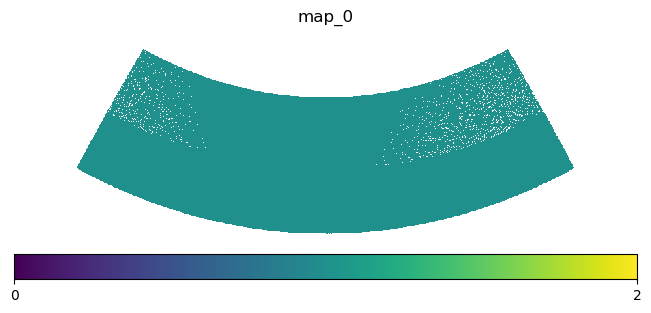

In [14]:
plot_healpix_stack([shifed_tng], rot=center_crafts, lonra=[-40, 40], latra=[-10,20], cmaps=['viridis'])

## crafts -> tng

In [15]:
center_crafts = [218, 42.5]
center_tng = [90, 0]

map_pix_shifted = shift_pixel_to_target(nside, map_pix, center_crafts, center_tng) 
len(map_pix_shifted)

321090

In [16]:
# test_values = np.random.random(size=(len(map_pix_tng_shifted))) + 1
test_values = np.full(len(map_pix_shifted), 1)
shifed_crafts = build_healpix_map(nside=nside, pixels=map_pix_shifted, values=test_values, unit_factor=1)

Figure saved to img_crafts_pixel_project.png!


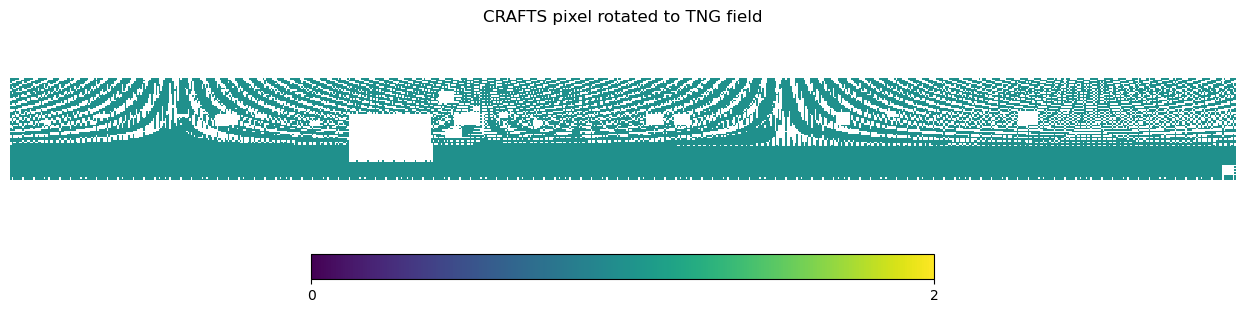

In [17]:
figpath = 'img_crafts_pixel_project.png'
plot_healpix_stack([shifed_crafts], rot=center_tng, lonra=[-30, 30], latra=[-5,5], cmaps=['viridis'], titles=['CRAFTS pixel rotated to TNG field'], save_path=figpath)

# select corresponding pixels

In [18]:
def find_positions(large_list, subset_list):
    """
    找到子集列表中每个元素在原始列表中最后一次出现的位置
    
    参数:
    large_list: 原始长列表
    subset_list: 子集列表
    
    返回:
    list: 子集中每个元素在原始列表中的位置索引列表
          如果元素不存在，对应位置为None
    """
    # 构建值到索引的映射字典（记录最后出现的位置）
    index_map = {}
    for idx, value in enumerate(large_list):
        index_map[value] = idx
    
    # 查找子集中每个元素的位置
    positions = []
    for value in subset_list:
        positions.append(index_map.get(value, None))
    return positions

In [19]:
flag = find_positions(map_pix_tng, map_pix_shifted)
len(flag), flag[:5]

(321090, [811370, 811371, 809324, 809325, 809326])

In [20]:
flag_dropnan = [i for i in flag if i is not None]
len(flag_dropnan)

321090

In [21]:
with h5.File(tng_data, 'r') as f:
    ind = 200
    tng_map_slice = f['temp_conv'][ind]
    tng_map_slice_cut = tng_map_slice[flag]
    freqs = f['freqs'][()]

In [22]:
filter_map = build_healpix_map(nside, map_pix, tng_map_slice_cut, unit_factor=1)
vmin, vmax = get_minmax(filter_map)

Figure saved to img_tng_mock_crafts.png!


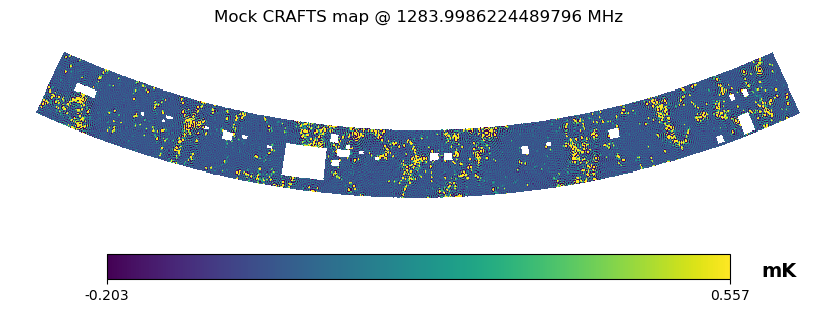

In [23]:
figpath = 'img_tng_mock_crafts.png'
titles=[f'Mock CRAFTS map @ {freqs[ind]} MHz']
plot_healpix_stack([filter_map], rot=center_crafts, mins=[vmin], maxs=[vmax], lonra=[-30, 30], latra=[-5,10], cmaps=['viridis'], units=['mK'], titles=titles, save_path=figpath)

## save mock map

In [24]:
output = '/work/home/liudy/data/tng100/tng_mock_crafts.h5'
with h5.File(output, 'a') as fo:
    fo.create_dataset(name='select_flag', data=flag)
    fo.create_dataset(name='map_pix', data=map_pix)
    with h5.File(tng_data, 'r') as f:
        # tng_map_cube = f['temp_conv'][()]
        # mock_crafts = tng_map_cube[:,flag]
        # fo.create_dataset(name='clean_map', data=mock_crafts) 
        for k,v in f.attrs.items():
            fo.attrs[k] = v

OSError: Unable to synchronously open file (bad object header version number)